# How Much Does Data Leakage Inflate Water Potability Prediction?
**A Leakage-Free Evaluation of Eight Classifiers** — notebook tái lập toàn bộ thực nghiệm.


## Bước 0. Cài thư viện và cấu hình

In [ ]:
!pip -q install imbalanced-learn xgboost lightgbm duckdb statsmodels
import warnings, json, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

SEED  = 42      # mọi bước ngẫu nhiên đều dùng seed này
QUICK = False   # True = lưới tham số nhỏ để chạy thử nhanh (kết quả KHÔNG khớp bài)
N_JOBS = -1     # dùng tất cả CPU
FEATS = ["ph","Hardness","Solids","Chloramines","Sulfate","Conductivity",
         "Organic_carbon","Trihalomethanes","Turbidity"]   # 9 chỉ số hoá lý
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12})

## Bước 1. Tải dữ liệu và kiểm tra nguồn
Bộ dữ liệu gốc: *Water Quality / Water Potability* của Aditya Kadiwal trên Kaggle (CC0).

In [ ]:
import hashlib, io, urllib.request
URL = "https://raw.githubusercontent.com/MainakRepositor/Datasets/master/water_potability.csv"
EXPECTED_MD5 = "a5eeae83d792e40da6c2f9e1eab945fc"
UPLOAD = False   # True nếu muốn tự upload file từ máy

if UPLOAD:
    from google.colab import files
    up = files.upload(); raw = list(up.values())[0]
else:
    raw = urllib.request.urlopen(URL, timeout=60).read()

md5 = hashlib.md5(raw).hexdigest()
print("MD5:", md5, "| khớp file trong bài:", md5 == EXPECTED_MD5)
d = pd.read_csv(io.BytesIO(raw))
X, y = d[FEATS], d["Potability"]

# Kiểm tra cơ bản (phải đúng với bài: 3.276 mẫu, 9 biến, 39% potable, 1.265 mẫu thiếu)
print("Kích thước:", d.shape)
print("Phân bố nhãn:", y.value_counts().to_dict(), f"-> {100*y.mean():.2f}% potable")
print("Số giá trị thiếu:", d.isna().sum()[d.isna().sum() > 0].to_dict())
print("Mẫu có ít nhất 1 giá trị thiếu:", int(d.isna().any(axis=1).sum()))
print("Số dòng trùng lặp:", int(d.duplicated().sum()))
assert d.shape == (3276, 10) and y.sum() == 1278
d.describe().T.round(3)

MD5: a5eeae83d792e40da6c2f9e1eab945fc | khớp file trong bài: True
Kích thước: (3276, 10)
Phân bố nhãn: {0: 1998, 1: 1278} -> 39.01% potable
Số giá trị thiếu: {'ph': 491, 'Sulfate': 781, 'Trihalomethanes': 162}
Mẫu có ít nhất 1 giá trị thiếu: 1265
Số dòng trùng lặp: 0


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.081,1.594,0.000,6.093,7.037,8.062,14.000
Hardness,3276.0,196.369,32.880,47.432,176.851,196.968,216.667,323.124
Solids,3276.0,22014.093,8768.571,320.943,15666.690,20927.834,27332.762,61227.196
Chloramines,3276.0,7.122,1.583,0.352,6.127,7.130,8.115,13.127
Sulfate,2495.0,333.776,41.417,129.000,307.699,333.074,359.950,481.031
Conductivity,3276.0,426.205,80.824,181.484,365.734,421.885,481.792,753.343
Organic_carbon,3276.0,14.285,3.308,2.200,12.066,14.218,16.558,28.300
Trihalomethanes,3114.0,66.396,16.175,0.738,55.845,66.622,77.337,124.000
Turbidity,3276.0,3.967,0.780,1.450,3.440,3.955,4.500,6.739
Potability,3276.0,0.390,0.488,0.000,0.000,0.000,1.000,1.000


## Bước 2. Chia train/test
Chia **trước tiên**, phân tầng theo nhãn (80/20). Tập test chỉ dùng **một lần** ở cuối. Mọi thống kê, lọc ngoại lệ, điền khuyết, chuẩn hoá, SMOTE về sau đều chỉ học từ tập train.

In [ ]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", Xtr.shape, "test:", Xte.shape)
print("tỷ lệ potable train/test: %.2f%% / %.2f%%" % (100*ytr.mean(), 100*yte.mean()))
tr = Xtr.copy(); tr["Potability"] = ytr.values      # bảng train dùng cho thống kê

train: (2620, 9) test: (656, 9)
tỷ lệ potable train/test: 39.01% / 39.02%


## Bước 3. Thống kê mô tả trên tập train (RQ1)
- Mann–Whitney U (hai phía) cho từng chỉ số, bỏ giá trị thiếu theo từng biến; hiệu ứng = rank-biserial `r = 2U/(n1·n0) − 1`; hiệu chỉnh **Holm** cho 9 phép thử.
- Brown–Forsythe (Levene theo trung vị) và Kolmogorov–Smirnov để so sánh độ phân tán / phân phối.
- Truy vấn SQL (DuckDB) tính tỷ lệ potable theo nhóm.

In [ ]:
from statsmodels.stats.multitest import multipletests
rows = []
for f in FEATS:
    a = tr.loc[(tr.Potability==1) & tr[f].notna(), f].values     # nhóm potable
    b = tr.loc[(tr.Potability==0) & tr[f].notna(), f].values     # nhóm non-potable
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rrb = 2*U/(len(a)*len(b)) - 1                                  # rank-biserial
    bf_p = stats.levene(a, b, center="median")[1]                  # Brown–Forsythe
    ks_D, ks_p = stats.ks_2samp(a, b)
    rows.append(dict(feature=f, n1=len(a), n0=len(b), med1=np.median(a), med0=np.median(b),
                     U=U, p_MW=p, r_rb=rrb, SD_ratio=a.std(ddof=1)/b.std(ddof=1),
                     p_BF=bf_p, KS_D=ks_D, p_KS=ks_p))
mw = pd.DataFrame(rows)
for c in ["p_MW","p_BF","p_KS"]:
    mw[c+"_holm"] = multipletests(mw[c], method="holm")[1]         # Holm trên 9 chỉ số
pd.set_option("display.width", 220)
print(mw[["feature","n1","n0","med1","med0","r_rb","p_MW","p_MW_holm"]].round(4).to_string(index=False))
print()
print(mw[["feature","SD_ratio","p_BF_holm","KS_D","p_KS_holm"]].round(4).to_string(index=False))

cm = tr.corr()
ff = cm.loc[FEATS, FEATS].values.copy(); np.fill_diagonal(ff, 0)
i, j = np.unravel_index(np.argmax(np.abs(ff)), ff.shape)
print("\nTương quan lớn nhất với nhãn: %.4f" % cm.loc[FEATS,"Potability"].abs().max())
print("Tương quan lớn nhất giữa 2 chỉ số: %s – %s = %.3f" % (FEATS[i], FEATS[j], ff[i,j]))

        feature   n1   n0       med1       med0    r_rb   p_MW  p_MW_holm
             ph  881 1352     7.0636     7.0135  0.0164 0.5113        1.0
       Hardness 1022 1598   197.5422   196.5954  0.0009 0.9696        1.0
         Solids 1022 1598 21150.7824 20717.1051  0.0222 0.3377        1.0
    Chloramines 1022 1598     7.1450     7.1035  0.0162 0.4826        1.0
        Sulfate  790 1205   332.9364   333.1483 -0.0063 0.8120        1.0
   Conductivity 1022 1598   425.5179   424.4713  0.0001 0.9964        1.0
 Organic_carbon 1022 1598    14.2029    14.2158 -0.0122 0.5968        1.0
Trihalomethanes  978 1508    66.6861    66.2848  0.0042 0.8598        1.0
      Turbidity 1022 1598     3.9661     3.9755  0.0038 0.8702        1.0

        feature  SD_ratio  p_BF_holm   KS_D  p_KS_holm
             ph    0.8692     0.0000 0.0591     0.3663
       Hardness    1.1610     0.0001 0.0439     1.0000
         Solids    1.0724     0.1714 0.0334     1.0000
    Chloramines    1.1242     0.0006 0.

In [ ]:
import duckdb
con = duckdb.connect(); con.register("w", tr)
print("--- Tỷ lệ potable (%) theo pH ---")
print(con.sql("""select case when ph is null then 'Missing pH' when ph<6.5 then 'Acidic (<6.5)'
      when ph<=8.5 then 'Compliant (6.5-8.5)' else 'Alkaline (>8.5)' end g, count(*) n, round(100*avg(Potability),2) p
      from w group by 1 order by 1""").df())
print("--- Theo Chloramines ---")
print(con.sql("""select case when Chloramines>8 then '>8 mg/L' else '<=8 mg/L' end g, count(*) n,
      round(100*avg(Potability),2) p from w group by 1 order by 1""").df())
print("--- Theo sulfate x hardness (so với trung bình TRAIN) ---")
print(con.sql("""select case when Sulfate>(select avg(Sulfate) from w) then 'High sulfate' else 'Normal/missing sulfate' end s,
      case when Hardness>(select avg(Hardness) from w) then 'high hardness' else 'normal hardness' end h,
      count(*) n, round(100*avg(Potability),2) p from w group by 1,2 order by 1,2""").df())
print("--- Có / không có giá trị thiếu ---")
print(con.sql("""select case when ph is null or Sulfate is null or Trihalomethanes is null then 'Has missing' else 'Complete' end g,
      count(*) n, round(100*avg(Potability),2) p from w group by 1 order by 1""").df())

--- Tỷ lệ potable (%) theo pH ---
                     g     n      p
0        Acidic (<6.5)   767  35.85
1      Alkaline (>8.5)   394  33.50
2  Compliant (6.5-8.5)  1072  44.22
3           Missing pH   387  36.43
--- Theo Chloramines ---
          g     n      p
0  <=8 mg/L  1895  37.94
1   >8 mg/L   725  41.79
--- Theo sulfate x hardness (so với trung bình TRAIN) ---
                        s                h    n      p
0            High sulfate    high hardness  464  42.67
1            High sulfate  normal hardness  514  36.77
2  Normal/missing sulfate    high hardness  859  37.72
3  Normal/missing sulfate  normal hardness  783  39.72
--- Có / không có giá trị thiếu ---
             g     n      p
0     Complete  1607  40.39
1  Has missing  1013  36.82


In [ ]:
# Chẩn đoán "độ thật" của dữ liệu (train): dấu hiệu dữ liệu mô phỏng / đã xử lý nhiều
print("pH nhỏ nhất / lớn nhất: %.2f / %.2f" % (tr.ph.min(), tr.ph.max()))
print("Tỷ lệ mẫu có Solids > 1000 mg/L: %.2f%%" % ((tr.Solids > 1000).mean()*100))
print("Tỷ lệ mẫu có Chloramines > 4 mg/L: %.2f%%" % ((tr.Chloramines.dropna() > 4).mean()*100))
print("Tỷ lệ mẫu có Turbidity > 5 NTU: %.2f%%" % ((tr.Turbidity > 5).mean()*100))
print("Tỷ lệ mẫu có Trihalomethanes > 80 µg/L: %.2f%%" % ((tr.Trihalomethanes.dropna() > 80).mean()*100))
pd.DataFrame({f: dict(mean=tr[f].mean(), sd=tr[f].std(), skew=stats.skew(tr[f].dropna()),
                      kurt=stats.kurtosis(tr[f].dropna()), normaltest_p=stats.normaltest(tr[f].dropna())[1])
              for f in FEATS}).T.round(3)

pH nhỏ nhất / lớn nhất: 0.23 / 13.54
Tỷ lệ mẫu có Solids > 1000 mg/L: 99.92%
Tỷ lệ mẫu có Chloramines > 4 mg/L: 97.21%
Tỷ lệ mẫu có Turbidity > 5 NTU: 9.81%
Tỷ lệ mẫu có Trihalomethanes > 80 µg/L: 18.79%


,mean,sd,skew,kurt,normaltest_p
ph,7.088,1.592,0.083,0.514,0.000
Hardness,196.521,32.638,-0.031,0.721,0.000
Solids,21888.068,8760.109,0.619,0.489,0.000
Chloramines,7.116,1.599,0.014,0.492,0.000
Sulfate,333.988,41.526,-0.047,0.720,0.000
Conductivity,427.916,80.944,0.241,-0.278,0.000
Organic_carbon,14.273,3.297,0.018,0.001,0.929
Trihalomethanes,66.143,16.215,-0.072,0.271,0.014
Turbidity,3.974,0.780,-0.018,-0.085,0.647


## Bước 4. Biểu đồ EDA (Fig 1, 3, 4)

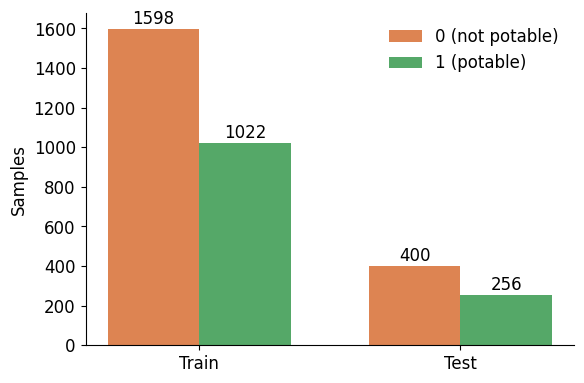

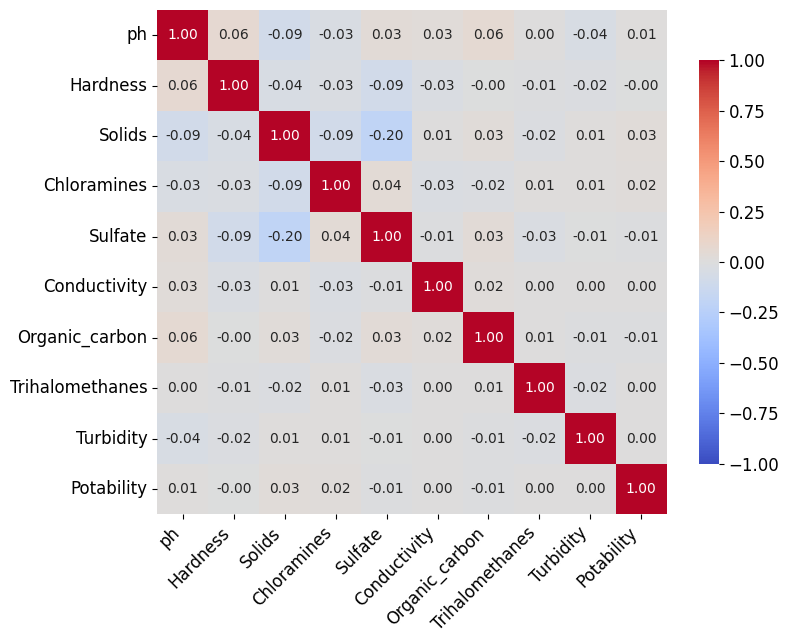

In [ ]:
# Fig 1: phân bố nhãn ở train và test
fig, ax = plt.subplots(figsize=(6,4)); w = 0.35
ax.bar([-w/2, 1-w/2], [(ytr==0).sum(), (yte==0).sum()], w, color="#DD8452", label="0 (not potable)")
ax.bar([ w/2, 1+w/2], [(ytr==1).sum(), (yte==1).sum()], w, color="#55A868", label="1 (potable)")
for xx, v in [(-w/2,(ytr==0).sum()), (w/2,(ytr==1).sum()), (1-w/2,(yte==0).sum()), (1+w/2,(yte==1).sum())]:
    ax.text(xx, v+25, str(v), ha="center")
ax.set_xticks([0,1]); ax.set_xticklabels(["Train","Test"]); ax.set_ylabel("Samples"); ax.legend(frameon=False)
ax.spines[["top","right"]].set_visible(False); fig.tight_layout(); fig.savefig("fig1_labels.png", dpi=200); plt.show()

# Fig 3: ma trận tương quan (train)
fig, ax = plt.subplots(figsize=(8.2,6.6))
sns.heatmap(tr[FEATS+["Potability"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax,
            annot_kws={"size":10}, cbar_kws={"shrink":0.8})
plt.xticks(rotation=45, ha="right"); fig.tight_layout(); fig.savefig("fig3_corr.png", dpi=200); plt.show()

## Bước 5. Pipeline không rò rỉ
1. **Lọc ngoại lệ IQR (2,0×)** chỉ trên hàng train của fold (ngưỡng tính từ fold đó); hàng có NaN được giữ lại.
2. **Điền khuyết bằng trung vị** (học từ fold train).
3. **StandardScaler** (học từ fold train).
4. **SMOTE** chỉ trên fold train, không bao giờ trên fold validation/test.
5. **Bộ phân loại**.

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn import FunctionSampler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (fbeta_score, f1_score, precision_score, recall_score, accuracy_score,
                             roc_auc_score, confusion_matrix, make_scorer)

def iqr_filter(Xa, ya, k=2.0):
    """Bỏ hàng có giá trị ngoài [Q1-k*IQR, Q3+k*IQR]. Ngưỡng tính từ CHÍNH dữ liệu truyền vào
    (tức fold train). So sánh với NaN là False nên hàng thiếu giá trị được giữ lại."""
    Xa = np.asarray(Xa, float)
    q1, q3 = np.nanpercentile(Xa, 25, axis=0), np.nanpercentile(Xa, 75, axis=0)
    lo, hi = q1 - k*(q3-q1), q3 + k*(q3-q1)
    bad = ((Xa < lo) | (Xa > hi)).any(axis=1)
    return Xa[~bad], np.asarray(ya)[~bad]

def make_pipe(clf):
    return ImbPipeline([("outlier", FunctionSampler(func=iqr_filter, validate=False)),
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler",  StandardScaler()),
                        ("smote",   SMOTE(random_state=SEED)),
                        ("clf",     clf)])

F05 = make_scorer(fbeta_score, beta=0.5, zero_division=0)   # F0.5: coi trọng Precision gấp đôi Recall

def metrics(yt, prob, t=0.5):
    yh = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0,1]).ravel()
    return dict(F05=fbeta_score(yt, yh, beta=0.5, zero_division=0)*100, F1=f1_score(yt, yh, zero_division=0)*100,
                Recall=recall_score(yt, yh, zero_division=0)*100, Precision=precision_score(yt, yh, zero_division=0)*100,
                Accuracy=accuracy_score(yt, yh)*100, AUC=roc_auc_score(yt, prob), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

def wilson(k, n, z=1.96):          # khoảng tin cậy Wilson 95% cho một tỷ lệ
    p = k/n; den = 1 + z*z/n; c = (p + z*z/(2*n))/den
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return 100*(c-h), 100*(c+h)

n_removed = len(Xtr) - len(iqr_filter(Xtr, ytr)[1])
print("Số mẫu train bị lọc ngoại lệ IQR:", n_removed)

Số mẫu train bị lọc ngoại lệ IQR: 61


## Bước 6. Huấn luyện 8 mô hình
Với mỗi mô hình: `GridSearchCV` (5-fold phân tầng, chấm **F0.5**) trên **tập train** → CV lặp 5×3 tại siêu tham số tốt nhất → xác suất out-of-fold để chọn **ngưỡng quyết định** (không dùng test) → đánh giá tập test **một lần**.
Mô hình cuối được chọn theo **F0.5 CV cao nhất** (trước khi nhìn test).

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate, RepeatedStratifiedKFold
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def models_and_grids():
    g = {
     "LR":  (LogisticRegression(max_iter=2000, random_state=SEED), {"clf__C": [0.01, 0.1, 1, 10]}),
     "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [5, 11, 21, 31, 51], "clf__weights": ["uniform","distance"]}),
     "NB":  (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]}),
     "DT":  (DecisionTreeClassifier(random_state=SEED),
             {"clf__max_depth": [4,6,8,10,12,15], "clf__min_samples_leaf": [1,5,10,20]}),
     "RF":  (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
             {"clf__max_depth": [6,10,None], "clf__min_samples_leaf": [1,5,10,20], "clf__max_features": ["sqrt", 0.5]}),
     "SVM": (SVC(kernel="rbf", probability=True, random_state=SEED),
             {"clf__C": [0.1,1,10], "clf__gamma": ["scale", 0.01, 0.1]}),
     "XGB": (XGBClassifier(random_state=SEED, n_jobs=1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5,
                           eval_metric="logloss", verbosity=0),
             {"clf__n_estimators": [200,400], "clf__max_depth": [3,6], "clf__learning_rate": [0.03,0.1], "clf__min_child_weight": [1,5]}),
     "LGBM":(LGBMClassifier(random_state=SEED, n_jobs=1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                            reg_lambda=5, verbose=-1),
             {"clf__n_estimators": [200,400], "clf__num_leaves": [15,31], "clf__learning_rate": [0.03,0.1], "clf__min_child_samples": [20,50]}),
    }
    if QUICK:   # lưới 1–2 giá trị để chạy thử
        g = {k: (m, {p: v[:2] for p, v in grid.items()}) for k, (m, grid) in g.items()}
    return g

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res, P_te, P_oof, P_tr, best_est = {}, {}, {}, {}, {}
T_GRID = np.round(np.arange(0.30, 0.701, 0.01), 2)      # các ngưỡng thử

for name, (clf, grid) in models_and_grids().items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), grid, scoring=F05, cv=cv, n_jobs=N_JOBS, refit=True).fit(Xtr, ytr)
    i = gs.best_index_; est = gs.best_estimator_
    r = dict(best_params={k.replace("clf__",""): v for k, v in gs.best_params_.items()},
             cv_f05_mean=gs.cv_results_["mean_test_score"][i]*100, cv_f05_std=gs.cv_results_["std_test_score"][i]*100)
    pte, ptr = est.predict_proba(Xte)[:,1], est.predict_proba(Xtr)[:,1]
    r["test_t05"], r["train_t05"] = metrics(yte, pte), metrics(ytr, ptr)          # ngưỡng mặc định 0.5
    # CV lặp 5x3 (chỉ trên train) tại siêu tham số đã chọn
    rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
    cr = cross_validate(clone(est), Xtr, ytr, cv=rcv, scoring={"f05": F05, "auc": "roc_auc"}, n_jobs=N_JOBS)
    r.update(rcv_f05_mean=cr["test_f05"].mean()*100, rcv_f05_std=cr["test_f05"].std()*100,
             rcv_auc_mean=cr["test_auc"].mean(), rcv_auc_std=cr["test_auc"].std())
    # xác suất out-of-fold trên train -> chọn ngưỡng KHÔNG dùng test
    oof = cross_val_predict(clone(est), Xtr, ytr, cv=cv, method="predict_proba", n_jobs=N_JOBS)[:,1]
    f05s = [fbeta_score(ytr, (oof >= t).astype(int), beta=0.5, zero_division=0) for t in T_GRID]
    r["oof_t"] = float(T_GRID[int(np.argmax(f05s))]); r["oof_f05"] = float(max(f05s)*100)
    r["test_at_oof_t"] = metrics(yte, pte, r["oof_t"])                              # áp ngưỡng đó lên test (1 lần)
    res[name], P_te[name], P_oof[name], P_tr[name], best_est[name] = r, pte, oof, ptr, est
    print(f"{name:5s} {r['best_params']} | CV F0.5 {r['cv_f05_mean']:.2f}±{r['cv_f05_std']:.2f} | "
          f"test F0.5 {r['test_t05']['F05']:.2f} AUC {r['test_t05']['AUC']:.3f} | t*={r['oof_t']:.2f} | {time.time()-t0:.0f}s", flush=True)

selected = max(res, key=lambda k: res[k]["cv_f05_mean"])      # chọn mô hình theo CV, KHÔNG theo test
print("\nMô hình được chọn theo F0.5 CV:", selected)

LR    {'C': 1} | CV F0.5 37.78±2.25 | test F0.5 41.23 AUC 0.499 | t*=0.42 | 4s
KNN   {'n_neighbors': 51, 'weights': 'distance'} | CV F0.5 52.13±1.76 | test F0.5 49.46 AUC 0.628 | t*=0.51 | 7s
NB    {'var_smoothing': 1e-09} | CV F0.5 44.90±1.34 | test F0.5 45.52 AUC 0.577 | t*=0.48 | 1s
DT    {'max_depth': 15, 'min_samples_leaf': 20} | CV F0.5 50.69±2.70 | test F0.5 47.25 AUC 0.593 | t*=0.57 | 7s
RF    {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1} | CV F0.5 55.90±0.80 | test F0.5 51.24 AUC 0.654 | t*=0.51 | 378s
SVM   {'C': 1, 'gamma': 'scale'} | CV F0.5 55.36±1.56 | test F0.5 51.62 AUC 0.645 | t*=0.55 | 97s
XGB   {'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 400} | CV F0.5 53.98±3.22 | test F0.5 51.87 AUC 0.654 | t*=0.52 | 39s
LGBM  {'learning_rate': 0.1, 'min_child_samples': 20, 'n_estimators': 400, 'num_leaves': 15} | CV F0.5 53.36±2.39 | test F0.5 49.24 AUC 0.642 | t*=0.50 | 31s

Mô hình được chọn theo F0.5 CV: RF


## Bước 7. Bảng kết quả

In [ ]:
names = ["LR","KNN","NB","DT","RF","SVM","XGB","LGBM"]
tab_cv = pd.DataFrame({n: dict(best_params=str(res[n]["best_params"]),
                               CV_F05=f'{res[n]["cv_f05_mean"]:.2f} ± {res[n]["cv_f05_std"]:.2f}',
                               repCV_F05=f'{res[n]["rcv_f05_mean"]:.2f} ± {res[n]["rcv_f05_std"]:.2f}',
                               repCV_AUC=f'{res[n]["rcv_auc_mean"]:.3f} ± {res[n]["rcv_auc_std"]:.3f}') for n in names}).T
print("Kết quả cross-validation (train) – dùng để CHỌN mô hình"); display(tab_cv)

tab_te = pd.DataFrame({n: res[n]["test_t05"] for n in names}).T.round(2)
print("Kết quả tập TEST, ngưỡng 0.5"); display(tab_te)

ts_sel = res[selected]["oof_t"]; m = res[selected]["test_at_oof_t"]
base = 100*(1 - yte.mean())
lo, hi = wilson(m["Accuracy"]/100*len(yte), len(yte))
print(f"{selected} tại ngưỡng t*={ts_sel:.2f}: TN={m['TN']} FP={m['FP']} FN={m['FN']} TP={m['TP']}")
print(f"Accuracy {m['Accuracy']:.2f}% (Wilson 95%: {lo:.1f}–{hi:.1f}%) | baseline luôn đoán 'non-potable' = {base:.2f}%")
print(f"Recall {m['Recall']:.1f}% | Precision {m['Precision']:.1f}% | F0.5 {m['F05']:.1f}%")

# Bảng ngưỡng cho mô hình được chọn: out-of-fold (train) và test (chỉ để minh hoạ)
rows = []
for t in [0.30,0.40,0.45,0.50,0.51,0.53,0.55,0.60,0.65]:
    o, e = metrics(ytr, P_oof[selected], t), metrics(yte, P_te[selected], t)
    rows.append(dict(t=t, oof_Recall=o["Recall"], oof_Prec=o["Precision"], oof_F05=o["F05"],
                     test_Recall=e["Recall"], test_Prec=e["Precision"], test_F05=e["F05"], test_FP=e["FP"]))
print("\nNgưỡng quyết định – mô hình", selected); display(pd.DataFrame(rows).round(1))

Kết quả cross-validation (train) – dùng để CHỌN mô hình


,best_params,CV_F05,repCV_F05,repCV_AUC
LR,{'C': 1},37.78 ± 2.25,38.44 ± 1.88,0.473 ± 0.020
KNN,"{'n_neighbors': 51, 'weights': 'distance'}",52.13 ± 1.76,51.94 ± 1.70,0.659 ± 0.021
NB,{'var_smoothing': 1e-09},44.90 ± 1.34,44.97 ± 2.03,0.573 ± 0.022
DT,"{'max_depth': 15, 'min_samples_leaf': 20}",50.69 ± 2.70,47.98 ± 3.12,0.610 ± 0.026
RF,"{'max_depth': None, 'max_features': 0.5, 'min_...",55.90 ± 0.80,54.65 ± 1.79,0.681 ± 0.012
SVM,"{'C': 1, 'gamma': 'scale'}",55.36 ± 1.56,54.66 ± 1.55,0.689 ± 0.020
XGB,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c...",53.98 ± 3.22,53.22 ± 2.63,0.669 ± 0.014
LGBM,"{'learning_rate': 0.1, 'min_child_samples': 20...",53.36 ± 2.39,53.18 ± 1.86,0.664 ± 0.016


Kết quả tập TEST, ngưỡng 0.5


,F05,F1,Recall,Precision,Accuracy,AUC,TN,FP,FN,TP
LR,41.23,44.02,49.61,39.56,50.76,0.50,206.0,194.0,129.0,127.0
KNN,49.46,52.05,57.03,47.87,58.99,0.63,241.0,159.0,110.0,146.0
NB,45.52,47.86,52.34,44.08,55.49,0.58,230.0,170.0,122.0,134.0
DT,47.25,49.91,55.08,45.63,56.86,0.59,232.0,168.0,115.0,141.0
RF,51.24,48.84,45.31,52.97,62.96,0.65,297.0,103.0,140.0,116.0
SVM,51.62,52.73,54.69,50.91,61.74,0.64,265.0,135.0,116.0,140.0
XGB,51.87,50.21,47.66,53.04,63.11,0.65,292.0,108.0,134.0,122.0
LGBM,49.24,47.85,45.70,50.21,61.13,0.64,284.0,116.0,139.0,117.0


RF tại ngưỡng t*=0.51: TN=311 FP=89 FN=144 TP=112
Accuracy 64.48% (Wilson 95%: 60.7–68.0%) | baseline luôn đoán 'non-potable' = 60.98%
Recall 43.8% | Precision 55.7% | F0.5 52.8%

Ngưỡng quyết định – mô hình RF


,t,oof_Recall,oof_Prec,oof_F05,test_Recall,test_Prec,test_F05,test_FP
0,0.3,92.0,43.1,48.3,91.4,42.9,48.0,312
1,0.4,75.7,47.7,51.5,71.1,47.3,50.7,203
2,0.4,64.1,52.6,54.5,57.0,49.0,50.4,152
3,0.5,49.6,57.2,55.5,45.3,53.0,51.2,103
4,0.5,47.0,58.8,56.0,43.8,55.7,52.8,89
5,0.5,40.6,60.1,54.9,37.1,56.5,51.2,73
6,0.6,35.3,61.8,53.8,34.0,58.8,51.3,61
7,0.6,25.9,67.6,51.2,25.8,66.0,50.3,34
8,0.6,17.3,72.8,44.4,20.3,76.5,49.2,16


### Bước 7b. Out-of-bag (OOB) chuẩn cho Random Forest

In [ ]:
#  Out-of-bag (OOB) chuẩn cho Random Forest 
# Tính OOB trên CÁC MẪU THẬT (sau IQR + điền trung vị + chuẩn hoá, KHÔNG dùng SMOTE),
# báo OOB ROC-AUC và OOB F0.5 (ở t=0.50 và t*=0.51) để so CÙNG THƯỚC ĐO với tập test.
rp = res["RF"]["best_params"]
mf = rp["max_features"]; mf = None if mf in ("None", None) else (float(mf) if mf not in ("sqrt","log2") else mf)
md_rf = None if rp["max_depth"] in ("None", None) else int(rp["max_depth"])

# (a) mẫu thật: IQR -> median -> scale, KHÔNG SMOTE
Xc, yc = iqr_filter(Xtr, ytr)
Xc_imp = SimpleImputer(strategy="median").fit_transform(Xc)
Xc_sc  = StandardScaler().fit_transform(Xc_imp)
rf_oob = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, oob_score=True,
            max_depth=md_rf, min_samples_leaf=int(rp["min_samples_leaf"]), max_features=mf).fit(Xc_sc, yc)
oob_p = rf_oob.oob_decision_function_[:, 1]
OOB = dict(auc=float(roc_auc_score(yc, oob_p)),
           f05_050=float(fbeta_score(yc,(oob_p>=0.50).astype(int),beta=0.5,zero_division=0)*100),
           f05_051=float(fbeta_score(yc,(oob_p>=0.51).astype(int),beta=0.5,zero_division=0)*100),
           acc=float(rf_oob.oob_score_))

# (b) con số OOB-accuracy trên dữ liệu ĐÃ SMOTE (lạc quan, chỉ để giải thích trong bài)
pipe_pre = ImbPipeline([("outlier",FunctionSampler(func=iqr_filter,validate=False)),
    ("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("smote",SMOTE(random_state=SEED))])
Xpp, ypp = pipe_pre.fit_resample(Xtr, ytr)
rf_sm = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, oob_score=True,
            max_depth=md_rf, min_samples_leaf=int(rp["min_samples_leaf"]), max_features=mf).fit(Xpp, ypp)
OOB["acc_smote"] = float(rf_sm.oob_score_)

cvgap = res["RF"]["cv_f05_mean"] - res["RF"]["test_t05"]["F05"]
print("OOB (mẫu thật):  ROC-AUC = %.3f | F0.5@0.50 = %.1f%% | F0.5@0.51 = %.1f%% | acc = %.3f"
      % (OOB["auc"], OOB["f05_050"], OOB["f05_051"], OOB["acc"]))
print("OOB-accuracy trên dữ liệu ĐÃ SMOTE (lạc quan) = %.3f  (test acc = %.1f%%)"
      % (OOB["acc_smote"], res["RF"]["test_t05"]["Accuracy"]))
print("Khoảng cách CV - Test F0.5 = %.1f điểm (thước đo trung thực nhất)" % cvgap)

## Biểu đồ kết quả (Fig 5, 6, 7)

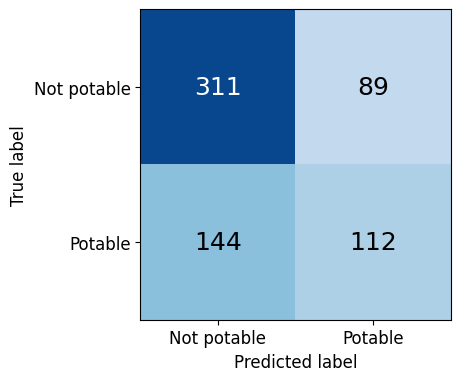

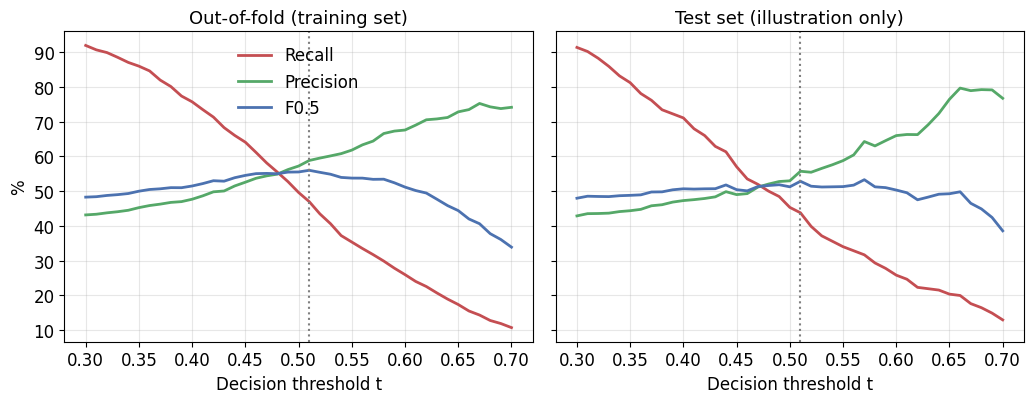

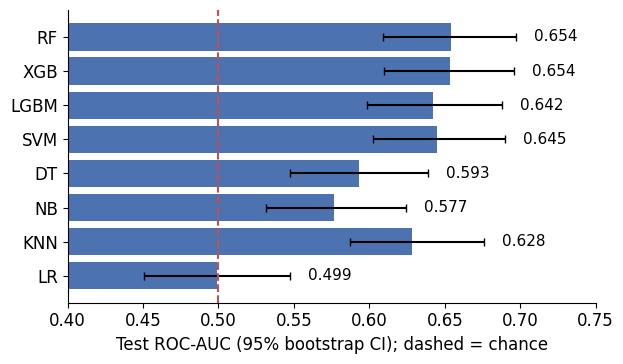

In [ ]:
sel = selected
# Fig 5: ma trận nhầm lẫn tại ngưỡng t* (test)
m = metrics(yte, P_te[sel], ts_sel); cmx = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
fig, ax = plt.subplots(figsize=(4.6,4.2)); ax.imshow(cmx, cmap="Blues", vmin=0, vmax=cmx.max()*1.1)
for i in range(2):
    for j in range(2): ax.text(j, i, str(cmx[i,j]), ha="center", va="center", fontsize=18, color="white" if cmx[i,j] > 180 else "black")
ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xticklabels(["Not potable","Potable"]); ax.set_yticklabels(["Not potable","Potable"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); fig.tight_layout(); fig.savefig("fig5_cm.png", dpi=200); plt.show()

# Fig 6: Recall / Precision / F0.5 theo ngưỡng (out-of-fold vs test)
fig, axs = plt.subplots(1, 2, figsize=(10.5,4.2), sharey=True)
for a, (yt, p, tt) in zip(axs, [(ytr, P_oof[sel], "Out-of-fold (training set)"), (yte, P_te[sel], "Test set (illustration only)")]):
    for k, c in [("Recall","#C44E52"), ("Precision","#55A868"), ("F05","#4C72B0")]:
        a.plot(T_GRID, [metrics(yt, p, t)[k] for t in T_GRID], color=c, lw=2, label="F0.5" if k == "F05" else k)
    a.axvline(ts_sel, color="gray", ls=":", lw=1.5); a.set_title(tt); a.set_xlabel("Decision threshold t"); a.grid(alpha=.3)
axs[0].set_ylabel("%"); axs[0].legend(frameon=False, loc="upper center"); fig.tight_layout(); fig.savefig("fig6_threshold.png", dpi=200); plt.show()

# Fig 7: ROC-AUC trên test với khoảng tin cậy bootstrap 95% (1000 lần lấy mẫu lại tập test)
order = ["LR","KNN","NB","DT","SVM","LGBM","XGB","RF"]; aucs, lo_, hi_ = [], [], []
for k in order:
    p = P_te[k]; rng = np.random.default_rng(1); yv = yte.values; b = []
    for _ in range(1000):
        ii = rng.integers(0, len(yv), len(yv)); b.append(roc_auc_score(yv[ii], p[ii]))
    aucs.append(roc_auc_score(yv, p)); l, h = np.percentile(b, [2.5, 97.5]); lo_.append(aucs[-1]-l); hi_.append(h-aucs[-1])
fig, ax = plt.subplots(figsize=(6.4,3.8)); ax.barh(order, aucs, xerr=[lo_, hi_], color="#4C72B0", capsize=3)
ax.axvline(0.5, color="#C44E52", ls="--"); ax.set_xlim(0.4, 0.75); ax.set_xlabel("Test ROC-AUC (95% bootstrap CI); dashed = chance")
for i, a_ in enumerate(aucs): ax.text(a_+0.012+hi_[i], i, f"{a_:.3f}", va="center", fontsize=11)
ax.spines[["top","right"]].set_visible(False); fig.tight_layout(); fig.savefig("fig7_auc.png", dpi=200); plt.show()

## Bước 8. Thí nghiệm rò rỉ dữ liệu — tách 2 nguồn (RQ3)

In [ ]:
# Thí nghiệm rò rỉ: TÁCH 2 NGUỒN, trên CÙNG 656 mẫu test thật 
# 4 chế độ (đều chấm trên đúng 656 mẫu test thật, dùng mô hình đã tune):
#   Clean        : pipeline chuẩn (fit trên train)  -> đã có ở P_te[...]
#   Preproc-only : Imputer + Scaler fit trên TOÀN BỘ 3,276 mẫu; SMOTE chỉ trên train
#   SMOTE-only   : Imputer + Scaler fit CHỈ trên train; SMOTE trên toàn bộ rồi bỏ mẫu test thật
#   Combined     : Imputer + Scaler + SMOTE đều fit trên toàn bộ rồi bỏ mẫu test thật
te_pos = [X.index.get_loc(i) for i in Xte.index]
mask_test = np.zeros(len(X), bool); mask_test[te_pos] = True
imp_all = SimpleImputer(strategy="median").fit(X); sc_all = StandardScaler().fit(imp_all.transform(X))
imp_tr  = SimpleImputer(strategy="median").fit(Xtr); sc_tr  = StandardScaler().fit(imp_tr.transform(Xtr))

def _pool(Xsc_all):                      # SMOTE trên toàn bộ rồi bỏ đúng các dòng test thật
    Xr, yr = SMOTE(random_state=SEED).fit_resample(Xsc_all, y)
    keep = np.ones(len(yr), bool); keep[:len(X)] = ~mask_test
    return Xr[keep], yr[keep]

# preproc-only
Xtr_po = sc_all.transform(imp_all.transform(Xtr)); Xte_po = sc_all.transform(imp_all.transform(Xte))
Xtr_po, ytr_po = SMOTE(random_state=SEED).fit_resample(Xtr_po, ytr)
# smote-only
Xall_tr = sc_tr.transform(imp_tr.transform(X)); Xte_so = sc_tr.transform(imp_tr.transform(Xte))
Xtr_so, ytr_so = _pool(Xall_tr)
# combined
Xall_all = sc_all.transform(imp_all.transform(X)); Xte_co = sc_all.transform(imp_all.transform(Xte))
Xtr_co, ytr_co = _pool(Xall_all)
MODES = {"preproc": (Xtr_po, ytr_po, Xte_po), "smote": (Xtr_so, ytr_so, Xte_so), "combined": (Xtr_co, ytr_co, Xte_co)}

def _boot_ci(yt, pa, pb, n=2000, seed=1):     # paired bootstrap CI cho dAUC trên 656 mẫu test
    rng = np.random.default_rng(seed); yt = np.asarray(yt); diffs = []
    for _ in range(n):
        ii = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[ii])) < 2: continue
        diffs.append(roc_auc_score(yt[ii], pb[ii]) - roc_auc_score(yt[ii], pa[ii]))
    return float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

def _tuned(name):   # tái tạo mô hình đã chọn từ best_params (dùng y hệt cho mọi chế độ)
    bp = res[name]["best_params"]; clf = clone(models_and_grids()[name][0])
    clf.set_params(**bp); return clf

leak = {}
for name in names:
    row = {"auc_clean": res[name]["test_t05"]["AUC"]}
    p_clean = P_te[name]
    for mode, (Xt, yt2, Xe) in MODES.items():
        est = _tuned(name).fit(Xt, yt2); p = est.predict_proba(Xe)[:, 1]; a = roc_auc_score(yte, p)
        row[f"auc_{mode}"] = float(a); row[f"d_{mode}"] = float(a - row["auc_clean"])
        if mode == "combined": row["d_lo"], row["d_hi"] = _boot_ci(yte.values, p_clean, p)
    leak[name] = row
    print("%-5s clean %.3f | preproc %.3f (%+.3f) | smote %.3f (%+.3f) | combined %.3f (%+.3f) [%.3f, %.3f]"
          % (name, row["auc_clean"], row["auc_preproc"], row["d_preproc"], row["auc_smote"], row["d_smote"],
             row["auc_combined"], row["d_combined"], row["d_lo"], row["d_hi"]), flush=True)
print("\\n=> Phần lớn mức thổi phồng đến từ SMOTE-before-split, không phải từ điền khuyết/chuẩn hoá.")

In [ ]:
# ===== Quy trình rò rỉ "nặng": chia TRÊN dữ liệu đã cân bằng (cho phụ lục) =====
Xi = imp_all.transform(X); Xs = sc_all.transform(Xi)
Xr, yr = SMOTE(random_state=SEED).fit_resample(Xs, y)
Xtr_b, Xte_b, ytr_b, yte_b = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=SEED)
leak_bal = {}
for name in names:
    est = _tuned(name).fit(Xtr_b, ytr_b); p = est.predict_proba(Xte_b)[:, 1]
    leak_bal[name] = metrics(yte_b, p)
    print("%-5s AUC %.3f Acc %.1f F0.5 %.1f" % (name, leak_bal[name]["AUC"], leak_bal[name]["Accuracy"], leak_bal[name]["F05"]))

In [ ]:
# ===== Độ ổn định của dAUC qua 10 lần chia ngẫu nhiên (seed 42..51), RF & KNN =====
rep = {"RF": [], "KNN": []}
for sd in range(42, 52):
    Xt2, Xe2, yt2, ye2 = train_test_split(X, y, test_size=0.2, stratify=y, random_state=sd)
    te2 = [X.index.get_loc(i) for i in Xe2.index]; m2 = np.zeros(len(X), bool); m2[te2] = True
    i2 = SimpleImputer(strategy="median").fit(X); s2 = StandardScaler().fit(i2.transform(X))
    Xa = s2.transform(i2.transform(X)); Xet = s2.transform(i2.transform(Xe2))
    Xr2, yr2 = SMOTE(random_state=SEED).fit_resample(Xa, y); k2 = np.ones(len(yr2), bool); k2[:len(X)] = ~m2
    for name in ["RF", "KNN"]:
        ec = make_pipe(_tuned(name)).fit(Xt2, yt2); ac = roc_auc_score(ye2, ec.predict_proba(Xe2)[:, 1])
        el = _tuned(name).fit(Xr2[k2], yr2[k2]);     al = roc_auc_score(ye2, el.predict_proba(Xet)[:, 1])
        rep[name].append(al - ac)
    print("seed %d  dAUC RF %+.3f | KNN %+.3f" % (sd, rep["RF"][-1], rep["KNN"][-1]), flush=True)
rep_summary = {k: dict(mean=float(np.mean(v)), sd=float(np.std(v, ddof=1))) for k, v in rep.items()}
print("\\nRF  : dAUC = %.3f ± %.3f" % (rep_summary["RF"]["mean"], rep_summary["RF"]["sd"]))
print("KNN : dAUC = %.3f ± %.3f" % (rep_summary["KNN"]["mean"], rep_summary["KNN"]["sd"]))

## Bước 9. Xuất bảng .tex và hình .png cho Overleaf

In [ ]:
# ===== Xuất toàn bộ bảng .tex và hình .png cho Overleaf =====
LAB = {"LR":"Logistic Regression","KNN":"k-Nearest Neighbors","NB":"Gaussian Naive Bayes","DT":"Decision Tree",
       "RF":"Random Forest","SVM":"SVM (RBF)","XGB":"XGBoost","LGBM":"LightGBM"}

# -- tab_leak.tex : 4 chế độ, cùng 656 mẫu test thật --
L = [r"{\footnotesize\setlength{\tabcolsep}{4pt}", r"\begin{tabular}{@{}lrrrr@{}}\toprule",
     r"Model & Clean & Preproc-only AUC ($\Delta$) & SMOTE-only AUC ($\Delta$) & Combined AUC ($\Delta$, 95\% CI) \\ \midrule"]
for k in names:
    c = leak[k]
    L.append(r"%s & %.3f & %.3f ($+%.3f$) & %.3f ($+%.3f$) & %.3f ($+%.3f$ [%.3f, %.3f]) \\" %
             (LAB[k], c["auc_clean"], c["auc_preproc"], c["d_preproc"], c["auc_smote"], c["d_smote"],
              c["auc_combined"], c["d_combined"], c["d_lo"], c["d_hi"]))
L.append(r"\bottomrule\end{tabular}}")
open("tab_leak.tex","w").write("\n".join(L))

# -- tab_leak_bal.tex (phụ lục) --
S = [r"\begin{tabular}{@{}lrrr@{}}\toprule", r"Model & Acc. & F$_{0.5}$ & AUC \\ \midrule"]
for k in names:
    o = leak_bal[k]; S.append(r"%s & %.1f & %.1f & %.3f \\" % (LAB[k], o["Accuracy"], o["F05"], o["AUC"]))
S.append(r"\bottomrule\end{tabular}"); open("tab_leak_bal.tex","w").write("\n".join(S))
print("Đã ghi tab_leak.tex, tab_leak_bal.tex")

# -- fig8_leak.png : Clean vs Combined, thứ tự model thống nhất --
ORDER = ["LR","NB","DT","SVM","XGB","LGBM","KNN","RF"]
clean = [leak[k]["auc_clean"] for k in ORDER]; comb = [leak[k]["auc_combined"] for k in ORDER]
fig, ax = plt.subplots(figsize=(7.2,4)); xx = np.arange(len(ORDER)); w = 0.38
ax.bar(xx-w/2, clean, w, color="#4C72B0", label="Leakage-free")
ax.bar(xx+w/2, comb, w, color="#C44E52", label="Leaky (impute+scale+SMOTE before isolating the test set)")
ax.axhline(0.5, color="gray", ls="--", lw=1); ax.set_xticks(xx); ax.set_xticklabels(ORDER)
ax.set_ylabel("Test ROC-AUC (same 656 real samples)"); ax.set_ylim(0.45,0.80)
ax.legend(frameon=False, fontsize=10, loc="upper left"); ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); fig.savefig("fig8_leak.png", dpi=220); plt.show()

# -- fig_ga.png : graphical abstract (ô 2 & 4 gọn trong khung; ô 4 = OOB ROC-AUC thật) --
from matplotlib.patches import FancyBboxPatch
rf_auc = res["RF"]["test_t05"]["AUC"]; rf_acc = res["RF"]["test_t05"]["Accuracy"]
d_rf = leak["RF"]["d_combined"]; d_lo = leak["RF"]["d_lo"]; d_hi = leak["RF"]["d_hi"]
cvgap = res["RF"]["cv_f05_mean"] - res["RF"]["test_t05"]["F05"]
figG = plt.figure(figsize=(10,7.2)); axG = figG.add_axes([0,0,1,1]); axG.set_xlim(0,100); axG.set_ylim(0,72); axG.axis("off")
def _bx(x,y,w,h,fc,ec="#2B5C73",lw=1.5): axG.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.2,rounding_size=1.2",fc=fc,ec=ec,lw=lw))
axG.add_patch(plt.Rectangle((0,62),100,10,fc="#1B4F66",ec="none"))
axG.text(50,68.4,"How Much Does Data Leakage Inflate Water Potability Prediction?",ha="center",va="center",color="white",fontsize=15,fontweight="bold")
axG.text(50,65.4,"A Leakage-Free Evaluation of Eight Classifiers",ha="center",va="center",color="white",fontsize=12,fontweight="bold")
axG.text(50,63.1,"Water Potability dataset (Kaggle, CC0)  |  3,276 samples  |  9 physicochemical indicators",ha="center",va="center",color="#DCEBF5",fontsize=9.5)
_bx(2,44,96,15,"#F4F9F4",ec="#2E7D32")
axG.text(4,57,"Leakage-free pipeline (80/20 stratified split; test set used once)",fontsize=12.5,fontweight="bold",color="#2E7D32",va="center")
_steps=["IQR x 2.0\noutlier filter","Median\nimputation","Standard-\nization","SMOTE","8 models\nGridSearchCV\n(F0.5, 5-fold)","Threshold from\nout-of-fold\nprobabilities","Test set:\nused once"]
for i,s in enumerate(_steps):
    x=4+i*13.5; _bx(x,47.3,12.2,8.0,"#E3F1E4" if i<5 else ("#EDE7F6" if i==5 else "#FCE8D5"))
    axG.text(x+6.1,51.3,s,ha="center",va="center",fontsize=9.3)
    if i<6: axG.annotate("",xy=(x+13.3,51.3),xytext=(x+12.3,51.3),arrowprops=dict(arrowstyle="-|>",color="#2E7D32",lw=1.4))
axG.text(50,45.2,"all steps before the classifier are fitted on training folds only",ha="center",fontsize=9.5,style="italic",color="#2E7D32")
_tiles=[("%.3f"%rf_auc,"Best test ROC-AUC\n(Random Forest); XGBoost\n0.654, SVM 0.645, LR 0.499"),
        ("%.1f%%"%rf_acc,"RF accuracy vs 61.0%\nmajority baseline; 95% CI\n60.7-68.0% contains it"),
        ("+%.3f"%d_rf,"ROC-AUC inflation from\nleakage (RF, same 656 real\ntest rows; CI %.3f-%.3f)"%(d_lo,d_hi)),
        ("%.3f"%OOB["auc"],"RF out-of-bag ROC-AUC on\nreal samples; CV-Test F0.5\ngap = %.1f pts (overfitting)"%cvgap)]
for i,(big,small) in enumerate(_tiles):
    x=2+i*24.5; _bx(x,27.5,23,13,"#EEF4F8")
    axG.text(x+11.5,37.2,big,ha="center",va="center",fontsize=18,fontweight="bold",color="#1B4F66")
    axG.text(x+11.5,31.0,small,ha="center",va="center",fontsize=8.0,linespacing=1.3)
caG=figG.add_axes([0.07,0.105,0.55,0.235]); xx2=np.arange(8)
caG.bar(xx2-0.19,clean,0.38,color="#4C72B0",label="Leakage-free"); caG.bar(xx2+0.19,comb,0.38,color="#C44E52",label="Leaky (same real test set)")
caG.axhline(.5,color="k",ls="--",lw=1); caG.set_xticks(xx2); caG.set_xticklabels(ORDER,fontsize=10.5); caG.set_ylim(.4,.82); caG.tick_params(labelsize=10)
caG.set_ylabel("Test ROC-AUC",fontsize=11); caG.legend(frameon=False,fontsize=9.5,loc="upper left"); caG.spines[["top","right"]].set_visible(False)
_bx(65,5,33,20,"#FFF8E6",ec="#B5651D")
axG.text(66.5,23,"Key findings",fontsize=12,fontweight="bold",color="#8A4B08",va="center")
_txt=("- No indicator differs in location\n  between classes (all Holm p = 1.0)\n"
      "- SMOTE-before-split causes almost\n  all of the leakage inflation\n"
      "- Leakage fabricates signal even for\n  Logistic Regression (0.499 -> 0.568)\n"
      "- Nine indicators cannot replace\n  laboratory testing")
axG.text(66.5,13.4,_txt,fontsize=9.0,va="center",linespacing=1.3)
axG.text(50,1.3,"Metrics on 656 held-out test samples; threshold and model chosen before the test set was used.",ha="center",fontsize=8.8,color="#555")
figG.savefig("fig_ga.png",dpi=200,facecolor="white"); plt.show()
print("Đã ghi fig8_leak.png và fig_ga.png")